# IR 3 — Compare actual data-carpentry outcomes

Compare the deliberately naïve **01 baseline** and **four worked examples 01a–01d**, trained with the same static IR 02 model. This short notebook reads actual saved runs and checks their current input hashes and matching training settings. Set `TRAIN_ALL = True` to regenerate all five model fits.

The examples combine unit handling, bounds/resampling and a distinct additional cleansing hypothesis. They are not a factorial experiment: differences cannot identify the effect of just one step. More elaborate carpentry is not guaranteed to improve prediction. Validation/test remain byte-identical across options, but different stopping times can confound comparisons; the table reports epochs and stopping reasons. These are single seeded fits, not uncertainty estimates.

Validation F1 uses thresholds tuned on validation itself and is therefore not an independent performance estimate. Explore policies with validation and reserve the test results for final reporting. Weighted BCE losses are not compared across options because training-derived class weights differ.

### Reading and presenting this notebook

The bullet points above each code cell explain what to notice; saved outputs remain visible. In **VS Code**, open the Command Palette (`Ctrl+Shift+P` on Windows/Linux, `Cmd+Shift+P` on macOS) and choose **Notebook: Collapse All Cell Inputs** (search for `Collapse All Cell Inputs`). Use **Expand All Cell Inputs** to edit, or expand an individual cell using its input control. Do not collapse outputs. VS Code can remember your previous view, so use the command if code is still shown. In **JupyterLab**, code inputs are initially hidden via notebook metadata; expand them with the left-hand cell collapser or the View menu. Hiding code does not disable execution or remove it from the file.


**What to notice**

- Locate the baseline and four worked carpentry strategies and choose a comparison output folder.
- TRAIN_ALL is off by default; turning it on executes the existing static trainer for all options.


In [1]:
from pathlib import Path
import hashlib, json, subprocess, sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

MODULE = Path.cwd()
if not (MODULE / '02_IR_Optimized_Training.ipynb').exists():
    MODULE = MODULE / '02_ir_functional_groups'
TRAIN_ALL = False  # True runs the existing IR 02 pipeline five times; no hyperparameter changes.
if TRAIN_ALL:
    subprocess.run([sys.executable, str(MODULE / 'run_carpentry_comparison.py')], check=True)

sys.path.insert(0, str(MODULE / 'examples'))
from strategies import STRATEGIES
OPTIONS = {'01 naive baseline': 'outputs/carpentry', **{s['name']: s['directory'] for s in STRATEGIES}}
OUTPUT = MODULE / 'outputs/carpentry_comparison'
OUTPUT.mkdir(parents=True, exist_ok=True)

**What to notice**

- Accept only completed runs whose dataset checksums, frozen holdouts, grid, labels, and training protocol match.
- Compare F1, sample counts, selected epoch, and stopping reason; flag missing/stale runs rather than inventing scores.
- These strategies bundle multiple edits, so a score difference does not isolate one cleansing step.


In [2]:
def file_hash(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

def protocol(doc):
    metadata = doc['data_manifest']
    return json.dumps({key: doc.get(key) for key in
                       ('model', 'training', 'torch', 'numpy', 'pandas')} |
                      {key: metadata[key] for key in ('labels', 'feature_count', 'wavenumber')},
                      sort_keys=True)

current_hashes = {
    directory: {split: file_hash(MODULE / directory / f'IR_{split}.parquet')
                for split in ('train', 'validation', 'test')}
    for directory in OPTIONS.values()
    if all((MODULE / directory / f'IR_{split}.parquet').exists() for split in ('train', 'validation', 'test'))
}
sys.path.insert(0, str(MODULE))
from ir_carpentry import validate_frozen_evaluation
for directory in current_hashes:
    manifest = json.loads((MODULE / directory / 'data_manifest.json').read_text(encoding='utf-8'))
    validate_frozen_evaluation(MODULE, MODULE / directory, manifest['wavenumber'])
baseline_hashes = current_hashes.get('outputs/carpentry', {})
for directory, hashes in current_hashes.items():
    if any(hashes[split] != baseline_hashes.get(split) for split in ('validation', 'test')):
        raise ValueError(f'{directory}: holdouts differ from baseline. Rerun all examples from the same IR 01 output.')

runs = []
for path in (MODULE / 'outputs/optimized_training').glob('run_*/run_documentation.json'):
    doc = json.loads(path.read_text(encoding='utf-8'))
    directory = doc.get('data_directory')
    if ('results' in doc and directory in current_hashes
            and doc.get('data_files_sha256') == current_hashes[directory]
            and (path.parent / 'test_metrics_by_label.csv').exists()):
        runs.append((path, doc))
runs.sort(key=lambda item: item[1]['created_utc'], reverse=True)
reference = next((doc for _, doc in runs if doc['data_directory'] == 'outputs/carpentry'),
                 runs[0][1] if runs else None)
rows, label_scores = [], {}
for option, directory in OPTIONS.items():
    eligible = [(path, doc) for path, doc in runs if doc['data_directory'] == directory
                and protocol(doc) == protocol(reference)]
    row = {'Method': option, 'Status': 'run IR 02 / stale or different settings'}
    if eligible:
        path, doc = eligible[0]
        results = doc['results']
        row.update(Status='ready', Train=doc['data_manifest']['rows']['train'],
                   Epoch=results['best_epoch'], **{
                       'Epochs run': results.get('epochs_run', np.nan), 'Stop': results.get('stop_reason', 'legacy'),
                       'Validation macro F1': results.get('validation_macro_f1', np.nan),
                       'Test macro F1': results['test_macro_f1'],
                       'Test micro F1': results['test_micro_f1'],
                       'Exact match': results['test_exact_match_accuracy'], 'Run': path.parent.name})
        per_label = pd.read_csv(path.parent / 'test_metrics_by_label.csv').set_index('label')
        label_scores[option] = per_label.test_F1.reindex(doc['data_manifest']['labels'])
        np.testing.assert_allclose(label_scores[option].mean(), results['test_macro_f1'])
    rows.append(row)

comparison = pd.DataFrame(rows).set_index('Method')
display(comparison.drop(columns='Run', errors='ignore').round(3))
if reference:
    settings = reference['training']
    scheduler_name = settings['scheduler'].get('name') if isinstance(settings['scheduler'], dict) else settings['scheduler']
    print(f"Training protocol: initial LR={settings.get('learning_rate', 'legacy')}; scheduler={scheduler_name}; seed={settings['seed']}.")
comparison.to_csv(OUTPUT / 'comparison.csv')
print('Latest compatible runs only; no test-based winner is selected. Missing options need a fresh IR 02 run.')

,Status,Train,Epoch,Epochs run,Stop,Validation macro F1,Test macro F1,Test micro F1,Exact match
Method,,,,,,,,,
01 naive baseline,ready,4848,272,288,robust_validation_slope,0.784,0.773,0.850,0.642
01a omit + deduplicate,ready,4525,285,293,robust_validation_slope,0.824,0.806,0.868,0.694
01b convert + label check,ready,4820,263,288,robust_validation_slope,0.829,0.804,0.866,0.679
01c pad + quality filter,ready,7914,563,574,robust_validation_slope,0.852,0.804,0.876,0.697
01d bin average + balance,ready,8563,563,574,robust_validation_slope,0.860,0.822,0.881,0.706


Training protocol: initial LR=1e-05; scheduler=CosineAnnealingWarmRestarts; seed=42.
Latest compatible runs only; no test-based winner is selected. Missing options need a fresh IR 02 run.


**What to notice**

- Compare aggregate F1 and per-functional-group test scores for compatible runs.
- Read both gains and regressions honestly; do not select another model by repeatedly optimizing the test set.


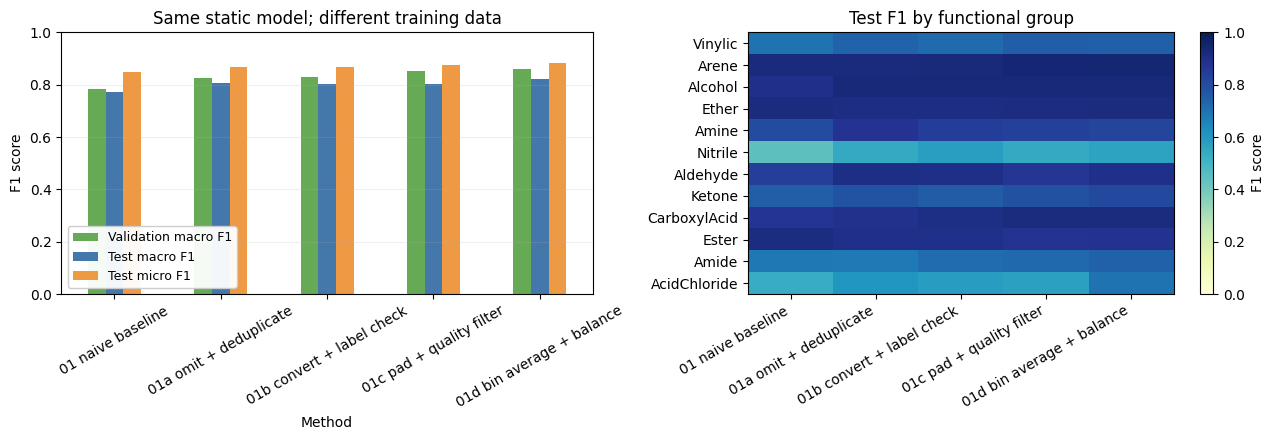

In [3]:
available = comparison.loc[comparison.Status.eq('ready')]
if available.empty:
    print('No compatible completed runs yet. Run IR 02 for each option, then rerun this notebook.')
else:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    available[['Validation macro F1', 'Test macro F1', 'Test micro F1']].plot.bar(
        ax=axes[0], color=['#66AA55', '#4477AA', '#EE9944'], rot=30)
    axes[0].set(title='Same static model; different training data', ylabel='F1 score', ylim=(0, 1))
    axes[0].legend(loc='lower left', fontsize=9, framealpha=.95)
    axes[0].grid(axis='y', alpha=.2)
    heatmap = pd.DataFrame(label_scores)
    image = axes[1].imshow(heatmap, vmin=0, vmax=1, cmap='YlGnBu', aspect='auto')
    axes[1].set_xticks(range(len(heatmap.columns)), heatmap.columns, rotation=30, ha='right')
    axes[1].set_yticks(range(len(heatmap.index)), heatmap.index)
    axes[1].set_title('Test F1 by functional group')
    fig.colorbar(image, ax=axes[1], label='F1 score')
    fig.tight_layout()
    fig.savefig(OUTPUT / 'comparison.png', dpi=160, bbox_inches='tight')
    plt.show()